## 1. Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2 . Installing kagglehub and Loading the Dataset

In [ ]:
%pip install kagglehub

In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path,"AB_NYC_2019.csv"))

## 3. Analysing the Data

In [114]:
df.head()


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [116]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [118]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [120]:
df.shape

(48895, 16)

## 4. Exploratory Data Analysis (EDA)

We explore the data in the standard order followed in an ML workflow:

- Missing values
- Univariate analysis 
- Bivariate analysis 
- Correlation between numeric features
- Outlier inspection

In [123]:
missing = df.isnull().sum()
missing[missing>0]

name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

In [112]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

<Axes: xlabel='room_type', ylabel='count'>

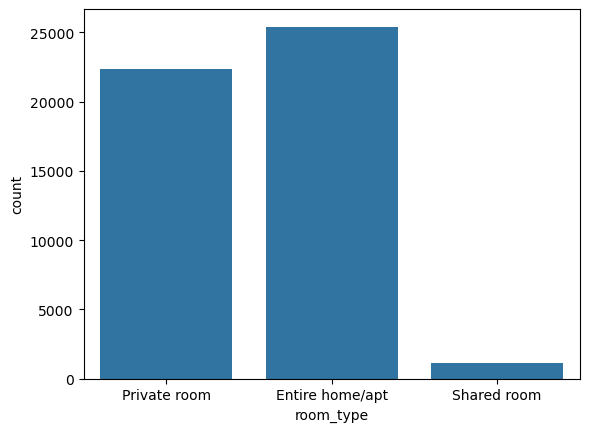

In [125]:
df['room_type'].unique()
df['room_type'].value_counts() #class imbalance as two have more no of values and one has less so we need to handle it or else model will be biased
sns.countplot(x='room_type', data = df)#SHared room is a minority

### Univariate Analysis - Numeric Features

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>],
       [<Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>]], dtype=object)

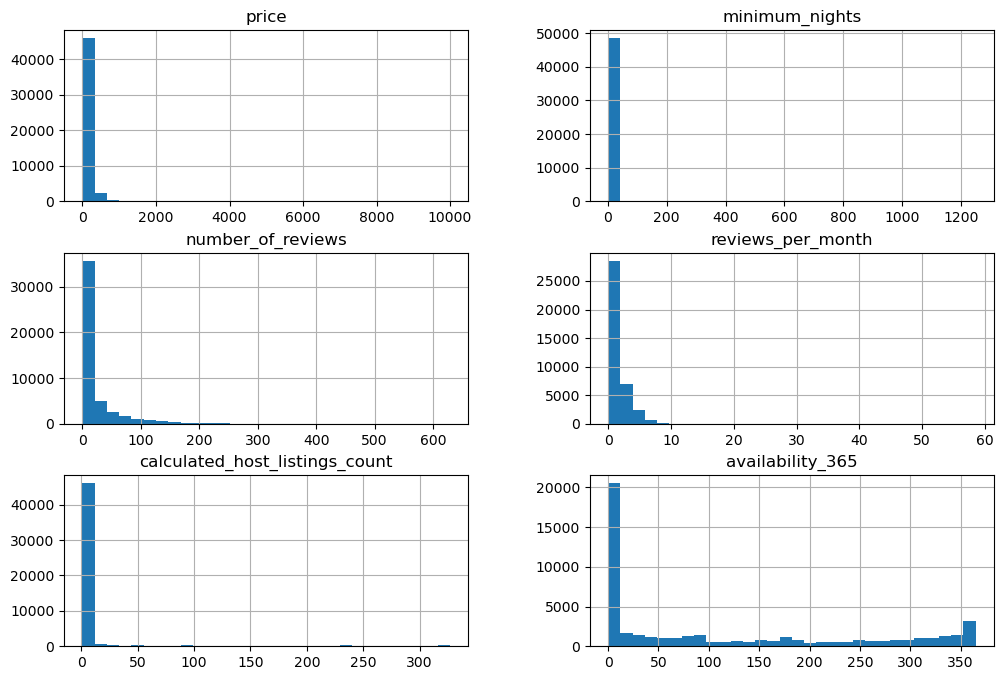

In [128]:
numerical_cols = ["price","minimum_nights","number_of_reviews","reviews_per_month","calculated_host_listings_count","availability_365"]
df[numerical_cols].hist(bins = 30, figsize = (12,8))

<Axes: xlabel='neighbourhood_group', ylabel='count'>

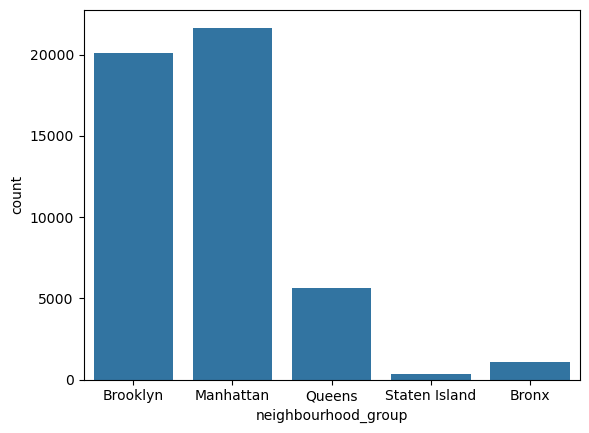

In [130]:
sns.countplot(data=df, x="neighbourhood_group")

### Bivariate Analysis- Features vs Target

<Axes: xlabel='room_type', ylabel='price'>

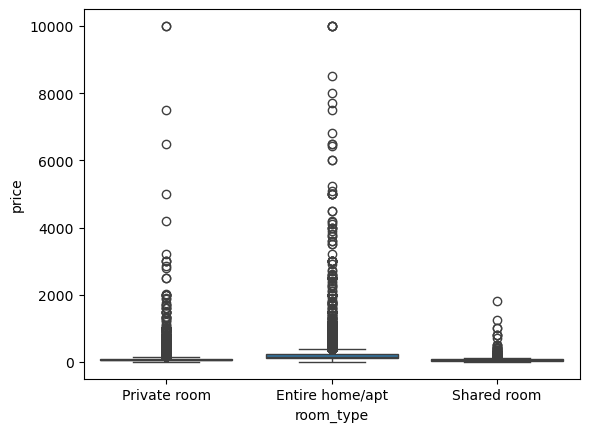

In [133]:
sns.boxplot(x='room_type', y= 'price', data = df)

### Correlation via heatmap

<Axes: >

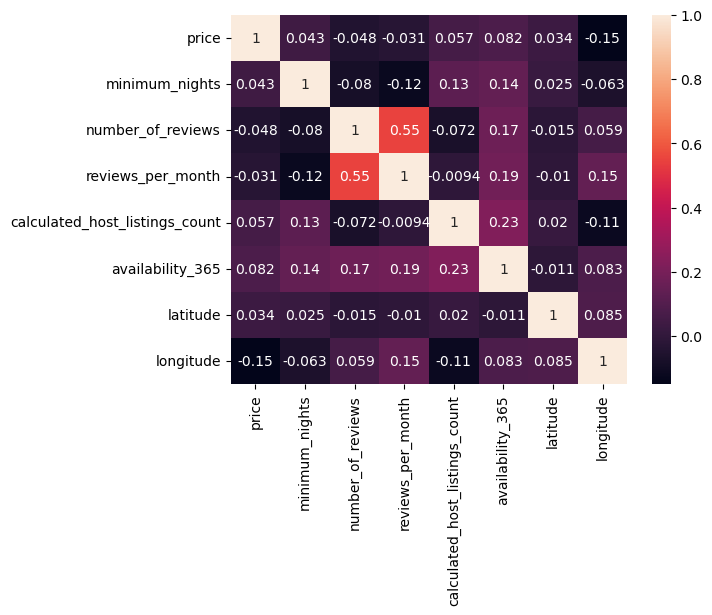

In [135]:
corr = df[numerical_cols +['latitude','longitude']].corr()
sns.heatmap(corr, annot=True)

<Axes: xlabel='longitude', ylabel='latitude'>

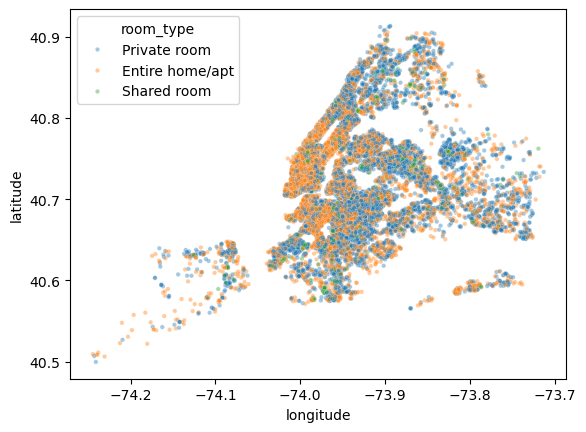

In [137]:
sns.scatterplot(x='longitude',y='latitude',data=df, hue ='room_type', alpha= 0.4, s=10)

## 5. Data Cleaning
 - Drop columns that are pure identifiers(id, name, host_id, host_name, last_review)
 - Fill missing reviews_per_month with 0(no reviews yet)
 - Cap extreme outliers in price and minimum_nights using percentile clipping, so they don't distort the model
 - Separate input features(X) and target variable(y)

In [139]:
df_clean = df.drop(columns=['id','name','host_id','host_name','last_review'])

df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)

df_clean

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...
48890,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,0.00,2,9
48891,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,0.00,2,36
48892,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,0.00,1,27
48893,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,0.00,6,2


In [142]:
# Cap Extreme outliers instead of deleting rows- replace the outlier with that upper limit
price_cap = df_clean['price'].quantile(0.99)
nights_cap = df_clean['minimum_nights'].quantile(0.99)

df_clean['price'] = df_clean['price'].clip(upper=price_cap)
df_clean['minimum_nights'] = df_clean['minimum_nights'].clip(upper = nights_cap)

df_clean

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...
48890,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,0.00,2,9
48891,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,0.00,2,36
48892,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,0.00,1,27
48893,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,0.00,6,2


In [144]:
X = df_clean.drop(columns=['room_type'])
y = df_clean['room_type']

## 6. Train/Test Split

We use stratified sampling here.

Stratified Sampling - preserves equal proportion of classes in both training and testing splits because the target is imbalanced.

In [147]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size =0.33, random_state=42, stratify=y)

In [149]:
df_clean[numerical_cols].skew()

price                             2.776321
minimum_nights                    2.360347
number_of_reviews                 3.690635
reviews_per_month                 3.300723
calculated_host_listings_count    7.933174
availability_365                  0.763408
dtype: float64

## 7. Preprocessing: ColumnTransformer+ Pipeline
- Numeric features - median imputation + standard scaling
- Categorical features - most-frequent imputation + one-hot encoding

We use ColumnTransformer which is basically a scikit learn tool that helps apply different preprocessing techniques to different columns of dataset.

In [152]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import warnings
warnings.filterwarnings('ignore')

In [154]:
numerical_cols = ["longitude","latitude","price","minimum_nights","number_of_reviews","reviews_per_month","calculated_host_listings_count","availability_365"]

categorical_cols = ["neighbourhood_group","neighbourhood"]

In [156]:
numeric_pipeline = Pipeline(steps = [
    ('impute', SimpleImputer(strategy = "median")),
    ('scale', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy ="most_frequent")),
    ('encode', OneHotEncoder(handle_unknown ='ignore'))
])

preprocessor = ColumnTransformer(transformers =[
    ("numerical", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

preprocessor                                

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['longitude', 'latitude', 'price',
                                  'minimum_nights', 'number_of_reviews',
                                  'reviews_per_month',
                                  'calculated_host_listings_count',
                                  'availability_365']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['neighbourhood_group', 'neighbourhood'])])

## 8. Trying Multiple ALgorithms
We try the following models:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
  
And perform 3-fold stratified cross validation on the training set.

In [159]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [161]:
models = {
    "Logistic Regression" : LogisticRegression(class_weight = "balanced",random_state = 42),
    "Decision Tree" : DecisionTreeClassifier(class_weight = "balanced", random_state = 42),
    "Random Forest" : RandomForestClassifier(class_weight = "balanced", random_state=42),
    "Gradient Boosting" : GradientBoostingClassifier(random_state = 42)
}

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor",preprocessor),("classifier", model)])
    accuracy=cross_val_score(pipe,X_train,y_train,cv=3,scoring="accuracy")
    macrof1 = cross_val_score(pipe,X_train,y_train,cv=3,scoring="f1_macro")

    print(f"{name} -> Accuracy: {accuracy.mean():.3f} , F1: {macrof1.mean():.3f}")

Logistic Regression -> Accuracy: 0.659 , F1: 0.522
Decision Tree -> Accuracy: 0.782 , F1: 0.650
Random Forest -> Accuracy: 0.850 , F1: 0.717
Gradient Boosting -> Accuracy: 0.850 , F1: 0.705


## 9. Hyperparameter Tuning

In [166]:
from sklearn.model_selection import RandomizedSearchCV

best_pipeline = Pipeline(steps =[
    ("preprocessor",preprocessor),
    ("classifier", RandomForestClassifier(class_weight = 'balanced'))
])

param_distribution = {
    "classifier__n_estimators" : [100,200,150,300],
    "classifier__max_depth" : [8,12,15,20, None],
    "classifier__min_samples_split":[2,5,10]
}

search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_distribution,
    n_iter=10,
    cv=3,
    scoring="f1_macro",
    random_state=42
)
search.fit(X_train,y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numerical',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['longitude',
                                                                                'latitude',
                                                                                'price',
                                                                                'minimum_nights',
                                                                                'number_of_reviews',
                                                                                'reviews_per_month',
                                                                                'calculated_host_listings_count',
                                                                                'availability_365']),
                                                                              ('categ...
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('encode',
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['neighbourhood_group',
                                                                                'neighbourhood'])])),
                                             ('classifier',
                                              RandomForestClassifier(class_weight='balanced'))]),
                   param_distributions={'classifier__max_depth': [8, 12, 15, 20,
                                                                  None],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     150,
                                                                     300]},
                   random_state=42, scoring='f1_macro')

In [167]:
print("Best Parameters: ",search.best_params_)
print("Best CV Macro-F1: ", search.best_score_)

Best Parameters:  {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__max_depth': None}
Best CV Macro-F1:  0.7332176610087698


## 10. Evaluation on the Test Set

In [174]:
 from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
best_pipeline = search.best_estimator_

y_pred = best_pipeline.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test,y_pred)}")
print(f"F1 Score: {f1_score(y_test,y_pred,average = "macro")}")

Accuracy Score: 0.8565939514129896
F1 Score: 0.7406228739580828


<Axes: >

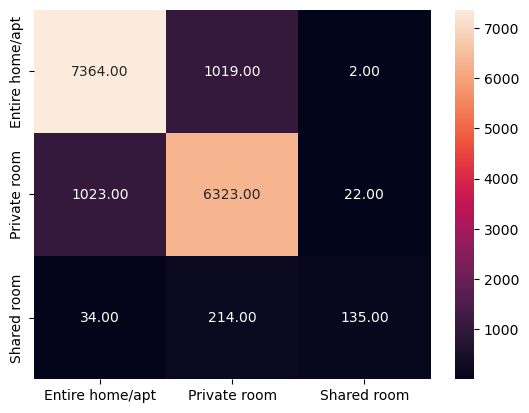

In [180]:
sns.heatmap(confusion_matrix(y_test,y_pred), annot=True,fmt="0.2f",xticklabels=best_pipeline.classes_,yticklabels=best_pipeline.classes_)

## 10. Saving the Final Model

In [182]:
import joblib

joblib.dump(best_pipeline, "Model_Pipeline.pkl")

['Model_Pipeline.pkl']